In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")



In [2]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [4]:
category_counts = df['category'].value_counts()
category_counts.head()


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [5]:
top_5_categories = category_counts.head(5)
top_5_categories


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

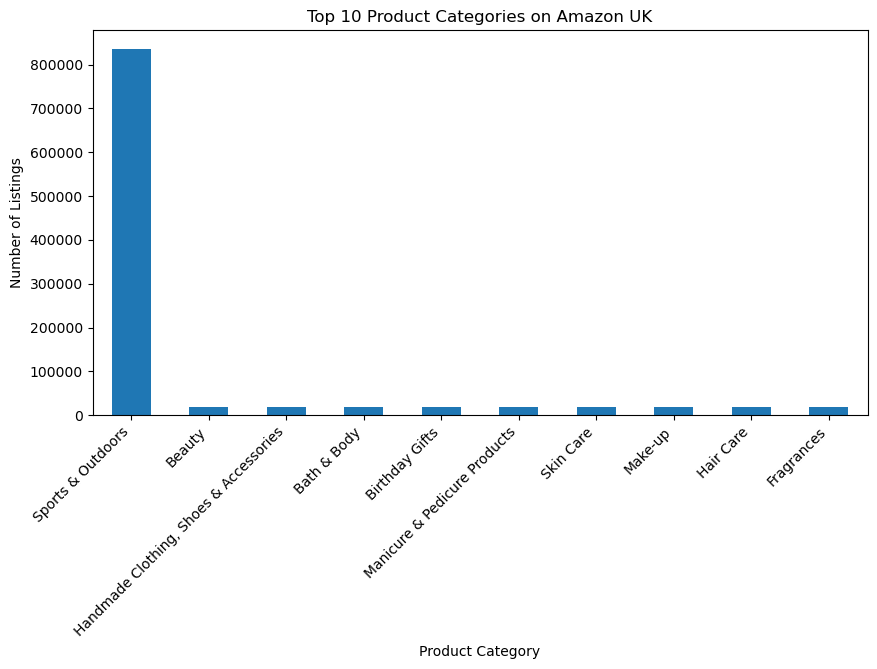

In [6]:
top_10_categories = category_counts.head(10)

plt.figure(figsize=(10, 5))
top_10_categories.plot(kind='bar')
plt.title("Top 10 Product Categories on Amazon UK")
plt.xlabel("Product Category")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45, ha='right')
plt.show()


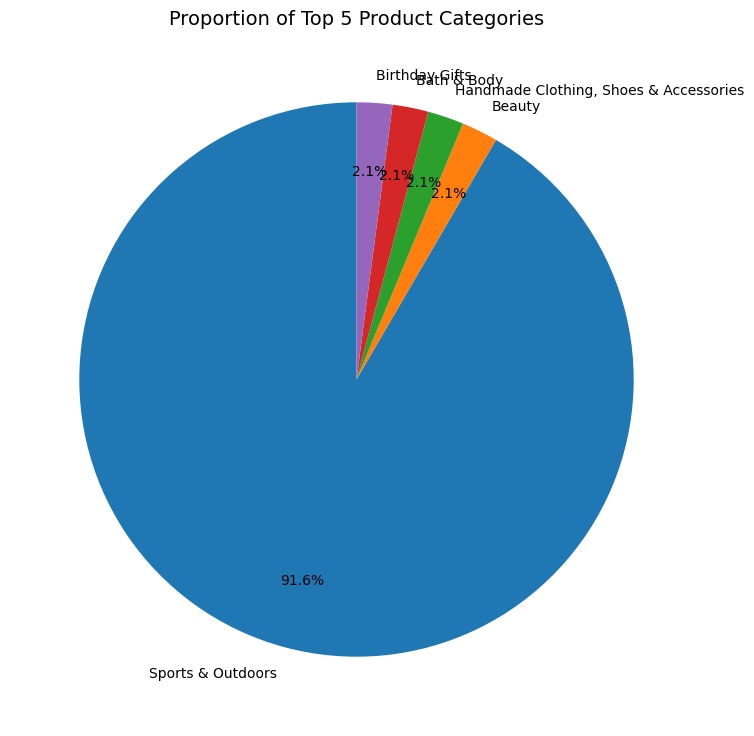

In [7]:
plt.figure(figsize=(9, 9))

top_5_categories.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.75,      
    labeldistance=1.1)

plt.title("Proportion of Top 5 Product Categories", fontsize=14)
plt.ylabel("")
plt.show()


The top categories are closely distributed, making variance less visually clear.

In [8]:
df['price'].head()

0    21.99
1    23.99
2    21.99
3    31.99
4    17.99
Name: price, dtype: float64

In [9]:
df['price'] = pd.to_numeric(df['price'], errors='coerce')

In [10]:
df_price = df[df['price'] > 0]

In [11]:
df_price.shape


(2443631, 9)

In [12]:
mean_price = df_price['price'].mean()
median_price = df_price['price'].median()
mode_price = df_price['price'].mode()[0]

mean_price, median_price, mode_price


(89.24453985892306, 19.09, 9.99)

The average price point of products listed on Amazon UK is higher than the most common price point (mode), showing that while most products are priced at lower, a smaller number of higher priced items increase the overall average.

In [13]:
price_variance = df_price['price'].var()
price_std = df_price['price'].std()
price_range = df_price['price'].max() - df_price['price'].min()
price_iqr = df_price['price'].quantile(0.75) - df_price['price'].quantile(0.25)

price_variance, price_std, price_range, price_iqr


(119446.39774346988, 345.61018177054603, 99999.99, 36.0)

Product prices on Amazon UK vary a lot, with most items priced low and a few very expensive products creating a wide price spread.

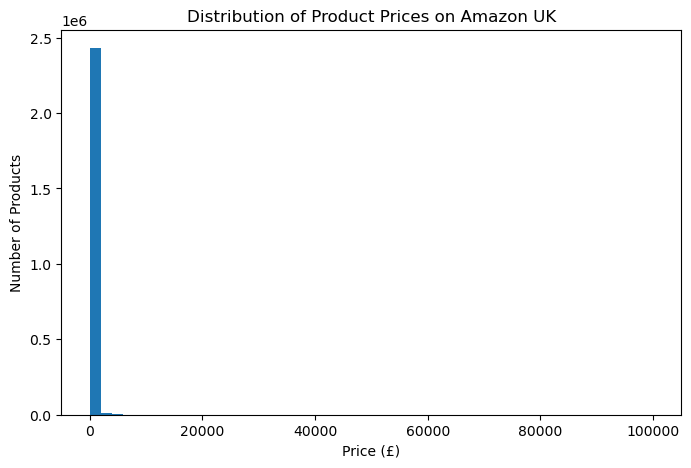

In [14]:
plt.figure(figsize=(8, 5))
plt.hist(df_price['price'], bins=50)
plt.title("Distribution of Product Prices on Amazon UK")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")
plt.show()


Hard to read, make it easier by putting realistic price ranges as shown below

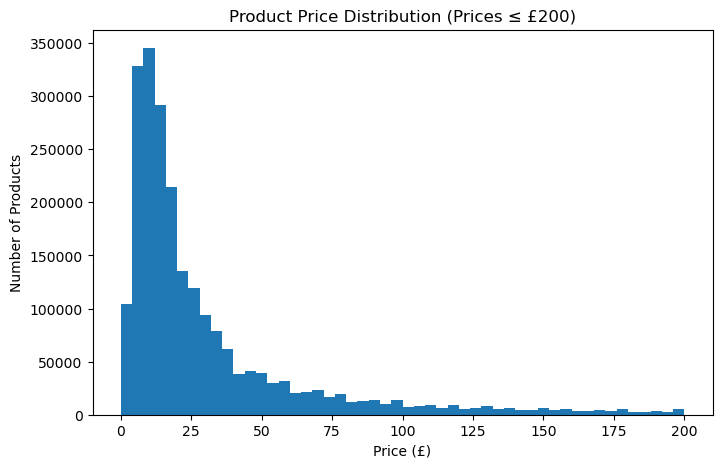

In [15]:
plt.figure(figsize=(8, 5))
plt.hist(df_price[df_price['price'] <= 200]['price'], bins=50)
plt.title("Product Price Distribution (Prices ≤ £200)")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")
plt.show()


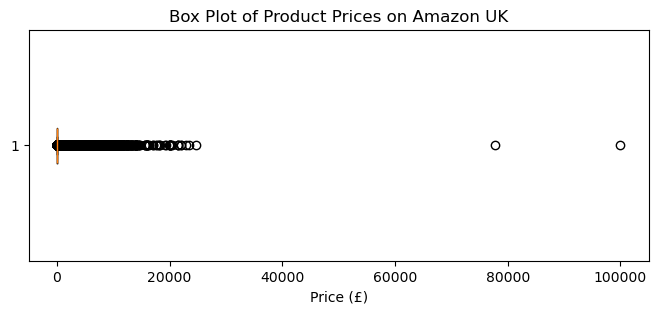

In [16]:
plt.figure(figsize=(8, 3))
plt.boxplot(df_price['price'], vert=False)
plt.title("Box Plot of Product Prices on Amazon UK")
plt.xlabel("Price (£)")
plt.show()


In [20]:
df['stars'].head()

df['stars'] = pd.to_numeric(df['stars'], errors='coerce')

df_rating = df[(df['stars'] >= 1) & (df['stars'] <= 5)]

df_rating.shape



(1218010, 9)

In [22]:
mean_rating = df_rating['stars'].mean()
median_rating = df_rating['stars'].median()
mode_rating = df_rating['stars'].mode()[0]

mean_rating, median_rating, mode_rating


(4.31916076222691, 4.4, 4.5)

Very positive customer ratings across the board. Mainly over 4.3 stars indicating overall customer satisfaction.

In [23]:
rating_variance = df_rating['stars'].var()
rating_std = df_rating['stars'].std()
rating_iqr = (
    df_rating['stars'].quantile(0.75)
    - df_rating['stars'].quantile(0.25)
)

rating_variance, rating_std, rating_iqr


(0.3083433752380519, 0.5552867504614637, 0.5)

Product ratings show low variation, this suggests that customer feedback is fairly consistent across products.

In [27]:
rating_skewness = df_rating['stars'].skew()
rating_kurtosis = df_rating['stars'].kurt()

rating_skewness, rating_kurtosis


(-2.3795681122127945, 9.78193769066435)

The ratings distribution is skewed towards higher values,meaning more customers give high ratings than low ones. This indicates that ratings are not normally distributed and tend to be more positive.

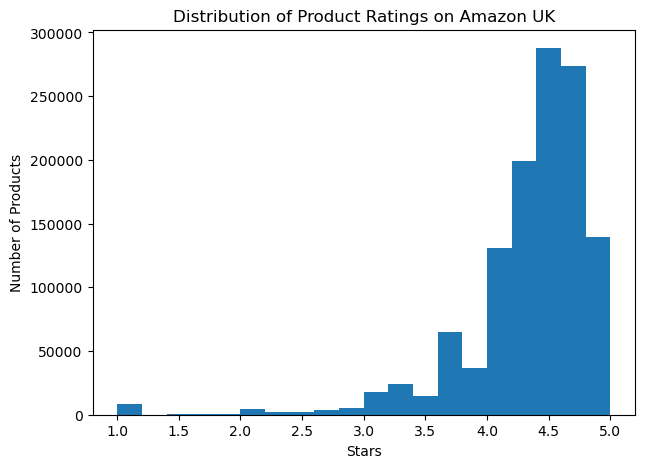

In [29]:
plt.figure(figsize=(7, 5))
plt.hist(df_rating['stars'], bins=20)
plt.title("Distribution of Product Ratings on Amazon UK")
plt.xlabel("Stars")
plt.ylabel("Number of Products")
plt.show()


The histogram shows that higher ratings are more common. This confirms that most products receive positive customer feedback.

Quick breakdown of all the findings,
Businesses should keep prices competitive, stand out in crowded categories, and use strong ratings to build trust and attract more customers.